# Recortes SAM

1. Toma la caja dibujada a mano en Roboflow.
2. Revisa con YOLO si hay personas dentro de la caja. **Esto es únicamente como una capa adicional de seguridad en caso de que en los recortes pudiera filtrarse algo e inspeccionar manualmente de forma más fácil**
3. SAM 2.1 saca la silueta de la vaca usando la caja como guía; todo lo demás se pinta de gris.
4. Hace tres recortes de 512 × 512 con relleno gris (`normal`, `mascara` y `mascara_clahe`); en el zip se guardan los dos con máscara.
5. Guarda `recortes_nube.zip` en `MyDrive/bcs_nube/`, que lee la libreta del modelo.


**Referencia:**

SAM: https://roboflow.com/blog/how-to-use-segment-anything-model-sam

## Configuración

In [ ]:
from pathlib import Path

CARPETA_TRABAJO = '/content/drive/MyDrive/bcs_nube'
LOCAL = Path('/content/datos')
PESOS = Path('/tmp/pesos')

MODELO_SAM   = 'sam2.1_b.pt'
MODELO_YOLO  = 'yolo11m.pt'      # solo para detectar personas
CONF_PERSONA = 0.35
MARGEN       = 0.05              # agranda la caja 5% por lado para el recorte
TAM_RECORTE  = 512
GRIS         = (114, 114, 114)
DILATAR      = 0.01              # agranda la máscara 1% del tamaño de la caja
RELLENAR_HUECOS = False

LIMITE_PRUEBA = None             # p. ej. 10 para una prueba rápida; None = todas
HILOS_COPIA   = 16               # copias en paralelo desde Drive
MOSTRAR_RECORTES = True          # sección 6: 12 recortes con máscara (revisión a ojo)

## Rutas

In [ ]:
import json, math, re, shutil, subprocess, sys, time, zipfile
from concurrent.futures import ThreadPoolExecutor

try:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
except ImportError:
    print('Fuera de Colab: se usan las rutas tal cual.')

import cv2, numpy as np, pandas as pd, torch
from PIL import Image, ImageDraw
from scipy.ndimage import binary_fill_holes
from ultralytics import SAM, YOLO
from IPython.display import display
pd.set_option('display.max_rows', 200); pd.set_option('display.width', 200)

rutas = json.loads((Path(CARPETA_TRABAJO) / 'rutas.json').read_text(encoding='utf-8'))
pendientes = [t for t, e in rutas.get('verificacion', {}).items() if e != 'OK']
assert not pendientes, f'La 00 dejó puntos por REVISAR: {pendientes}'
RAIZ_DATOS, RUTA_TABLA, RUTA_ROBOFLOW = Path(rutas['RAIZ_DATOS']), Path(rutas['RUTA_TABLA']), Path(rutas['RUTA_ROBOFLOW'])
print('Datos en Drive:', RAIZ_DATOS, '· Roboflow:', RUTA_ROBOFLOW.name)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else
      'NO HAY: Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4), y vuelve a ejecutar todo')

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Datos en Drive: /content/drive/MyDrive/lecheros/Dataset · Roboflow: roboflow_export_completo.zip
GPU: Tesla T4


## Fotos a procesar

Seleccionamos únicamente las fotos del rancho marcadas para usar (sin tomas de lado; las personas se revisan después con YOLO) y las copia rápidamente de Google Drive a la memoria de Colab para trabajarlas.

In [ ]:
def a_bool(v):
    return str(v).strip().lower() in {'true', '1', 'verdadero', 'si', 'sí', 'yes', 'x'}

def a_relativa(r):
    m = re.search(r'(?:^|/)(clean/.+)$', str(r).replace('\\', '/'))
    return m.group(1) if m else None

tabla = pd.read_csv(RUTA_TABLA)
tabla['id_vaca'] = tabla['id_vaca'].astype(str).str.replace(r'\.0$', '', regex=True)
tabla['animal'] = tabla['animal'].astype(str).str.replace(r'\.0$', '', regex=True)
tabla['archivo_limpio'] = tabla['archivo_limpio'].map(a_relativa)
fotos = tabla[(tabla['fuente'] == 'rancho') & (tabla['estado'] == 'ok') & tabla['usar'].map(a_bool)
              & (tabla['vista'].fillna('') != 'lateral') & tabla['archivo_limpio'].notna()].copy()
fotos['stem'] = fotos['archivo_limpio'].map(lambda r: Path(r).stem)
assert not fotos['stem'].duplicated().any(), 'Hay dos fotos con el mismo nombre: no se pueden emparejar con Roboflow'
if LIMITE_PRUEBA:
    fotos = fotos.groupby('ronda', group_keys=False).head(max(1, LIMITE_PRUEBA // 2))
    print(f'MODO PRUEBA: solo {len(fotos)} fotos')
fotos = fotos.reset_index(drop=True)
print(f"Fotos a procesar: {len(fotos)} · sesiones: {fotos['id_vaca'].nunique()}")

def copiar(rel):
    destino = LOCAL / rel
    if not destino.exists():
        destino.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(RAIZ_DATOS / rel, destino)
inicio = time.time()
with ThreadPoolExecutor(HILOS_COPIA) as ej:
    list(ej.map(copiar, fotos['archivo_limpio']))
ZIP_LOCAL = LOCAL / 'roboflow' / RUTA_ROBOFLOW.name
if not ZIP_LOCAL.exists():
    ZIP_LOCAL.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(RUTA_ROBOFLOW, ZIP_LOCAL)
print(f'Copia local lista en {time.time() - inicio:.0f} s')
DATOS = LOCAL                    # a partir de aquí se trabaja sobre la copia local
SALIDA = DATOS / 'recortes'
fotos.groupby('ronda').agg(fotos=('stem', 'size'), sesiones=('id_vaca', 'nunique'))

Fotos a procesar: 608 · sesiones: 93
Copia local lista en 60 s


,fotos,sesiones
ronda,,
1,259,24
2,349,69


## Roboflow correción

Roboflow renombra los archivos al exportar (`1213_dorsal_01_jpg.rf.a1b2c3.jpg`); aquí se recupera el nombre original. Etiqueta vacía → `sin_caja`; foto que no está en la exportación → `no_exportada`; más de una caja → la más grande y aviso `varias_cajas`.

In [ ]:
PATRON_RF = re.compile(r'^(?P<stem>.+)_(?:jpe?g|png|heic)\.rf\.[0-9a-zA-Z]+$', re.I)

def leer_cajas(texto):
    cajas = []
    for linea in texto.splitlines():
        v = [float(x) for x in linea.split()]
        if len(v) == 5:                        # clase xc yc w h
            _, xc, yc, w, h = v
        elif len(v) > 5:                       # polígono → su caja
            xs, ys = v[1::2], v[2::2]
            xc, yc, w, h = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2, max(xs) - min(xs), max(ys) - min(ys)
        else:
            continue
        cajas.append((xc, yc, w, h))
    return cajas

etiquetas = {}
with zipfile.ZipFile(ZIP_LOCAL) as zf:
    for n in zf.namelist():
        p = Path(n)
        if p.parent.name == 'labels' and p.suffix == '.txt':
            m = PATRON_RF.match(p.stem)
            etiquetas[m.group('stem') if m else p.stem] = leer_cajas(zf.read(n).decode())
print(f'Etiquetas en la exportación: {len(etiquetas)}')

filas = []
for _, f in fotos.iterrows():
    with Image.open(DATOS / f['archivo_limpio']) as im:
        ancho, alto = im.size
    fila = {'ancho': ancho, 'alto': alto, 'estado_recorte': 'ok', 'avisos': ''}
    if f['stem'] not in etiquetas:
        fila['estado_recorte'] = 'no_exportada'
    elif not etiquetas[f['stem']]:
        fila['estado_recorte'] = 'sin_caja'
    else:
        cajas = sorted(etiquetas[f['stem']], key=lambda c: c[2] * c[3], reverse=True)
        if len(cajas) > 1:
            fila['avisos'] = 'varias_cajas'
        xc, yc, w, h = cajas[0]
        fila.update(xc=xc, yc=yc, wn=w, hn=h,
                    x1=max(0, (xc - w / 2) * ancho), y1=max(0, (yc - h / 2) * alto),
                    x2=min(ancho, (xc + w / 2) * ancho), y2=min(alto, (yc + h / 2) * alto))
    filas.append(fila)
fotos = pd.concat([fotos.drop(columns=['ancho', 'alto'], errors='ignore'), pd.DataFrame(filas)], axis=1)
print(pd.crosstab(fotos['ronda'], fotos['estado_recorte']).to_string())

Etiquetas en la exportación: 704
estado_recorte  no_exportada   ok
ronda                            
1                          0  259
2                          4  345


## Avisos de control (Revisión manual)

El sistema genera alertas automáticas para que puedas revisar rápidamente a ojo las fotos dudosas:

*   **`persona_en_caja`**: Se activa si detecta que hay una persona o su ropa metida en la zona de la vaca.
*   **`mascara_dudosa`**: Se activa si la silueta recortada de la vaca quedó muy pequeña o excesivamente grande.
*   **`foto_compartida`**: Se activa si en la misma foto aparecen registradas dos vacas diferentes.

In [ ]:
PESOS.mkdir(parents=True, exist_ok=True)
sam = SAM(str(PESOS / MODELO_SAM))              # se descarga sola la primera vez
detector = YOLO(str(PESOS / MODELO_YOLO))
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def personas_en_caja(img_rgb, caja):
    # Fracción máxima de una persona detectada que cae dentro de la caja de la vaca
    r = detector(np.ascontiguousarray(img_rgb[..., ::-1]), classes=[0], conf=CONF_PERSONA, verbose=False)[0]
    x1, y1, x2, y2 = caja
    maximo = 0.0
    for px1, py1, px2, py2 in r.boxes.xyxy.cpu().numpy():
        inter = max(0, min(x2, px2) - max(x1, px1)) * max(0, min(y2, py2) - max(y1, py1))
        maximo = max(maximo, inter / max(1e-6, (px2 - px1) * (py2 - py1)))
    return maximo

def mascara_sam(img_rgb, caja):
    r = sam(np.ascontiguousarray(img_rgb[..., ::-1]), bboxes=[list(caja)], verbose=False)[0]
    m = r.masks.data[0].cpu().numpy().astype(np.uint8)
    # quita fragmentos sueltos muy pequeños (< 2% de la máscara) sin perder partes separadas por un poste
    n, etiquetas_cc, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n > 2:
        total = stats[1:, cv2.CC_STAT_AREA].sum()
        for i in range(1, n):
            if stats[i, cv2.CC_STAT_AREA] < 0.02 * total:
                m[etiquetas_cc == i] = 0
    if RELLENAR_HUECOS:
        m = binary_fill_holes(m).astype(np.uint8)
    lado = max(1, round(DILATAR * max(caja[2] - caja[0], caja[3] - caja[1])))
    m = cv2.dilate(m, np.ones((2 * lado + 1, 2 * lado + 1), np.uint8))
    x1, y1, x2, y2 = [round(v) for v in caja]
    dentro = np.zeros_like(m); dentro[y1:y2, x1:x2] = 1          # nada fuera de la caja
    return (m & dentro).astype(bool)

def letterbox(arr, tam=TAM_RECORTE):
    img = Image.fromarray(arr)
    esc = tam / max(img.size)
    nuevo = img.resize((max(1, round(img.width * esc)), max(1, round(img.height * esc))), Image.LANCZOS)
    lienzo = Image.new('RGB', (tam, tam), GRIS)
    lienzo.paste(nuevo, ((tam - nuevo.width) // 2, (tam - nuevo.height) // 2))
    return lienzo

def aplicar_clahe(arr):
    lab = cv2.cvtColor(arr, cv2.COLOR_RGB2LAB)
    lab[..., 0] = clahe.apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

if SALIDA.exists():
    shutil.rmtree(SALIDA)                 # corrida limpia
nuevas = {c: [] for c in ['archivo_recorte', 'archivo_mascara', 'archivo_mascara_clahe', 'area_mascara', 'persona']}
inicio = time.time()
for i, f in fotos.iterrows():
    if f['estado_recorte'] != 'ok':
        for c in nuevas:
            nuevas[c].append(None if c.startswith('archivo') else np.nan)
        continue
    img = np.array(Image.open(DATOS / f['archivo_limpio']).convert('RGB'))
    caja = (f['x1'], f['y1'], f['x2'], f['y2'])
    persona = personas_en_caja(img, caja)
    mask = mascara_sam(img, caja)
    area = mask.sum() / max(1, (caja[2] - caja[0]) * (caja[3] - caja[1]))
    w, h = caja[2] - caja[0], caja[3] - caja[1]
    X1, Y1 = max(0, round(caja[0] - MARGEN * w)), max(0, round(caja[1] - MARGEN * h))
    X2, Y2 = min(img.shape[1], round(caja[2] + MARGEN * w)), min(img.shape[0], round(caja[3] + MARGEN * h))
    recorte, m = img[Y1:Y2, X1:X2], mask[Y1:Y2, X1:X2]
    variantes = {'normal': recorte,
                 'mascara': np.where(m[..., None], recorte, np.array(GRIS, np.uint8)),
                 'mascara_clahe': np.where(m[..., None], aplicar_clahe(recorte), np.array(GRIS, np.uint8))}
    for carpeta, arr in variantes.items():
        destino = SALIDA / carpeta / f['id_vaca'] / f"{f['stem']}.jpg"
        destino.parent.mkdir(parents=True, exist_ok=True)
        letterbox(arr).save(destino, 'JPEG', quality=95)
        nuevas['archivo_recorte' if carpeta == 'normal' else f'archivo_{carpeta}'].append(destino.relative_to(DATOS).as_posix())
    nuevas['area_mascara'].append(round(float(area), 3))
    nuevas['persona'].append(round(persona, 2))
    if (i + 1) % 50 == 0:
        print(f'{i + 1}/{len(fotos)} · {time.time() - inicio:.0f} s')
for c, v in nuevas.items():
    fotos[c] = v

def sumar_aviso(actual, nuevo):
    return nuevo if not actual else f'{actual}+{nuevo}'
for condicion, aviso in [(fotos['persona'] > 0.2, 'persona_en_caja'),
                         ((fotos['area_mascara'] < 0.25) | (fotos['area_mascara'] > 0.95), 'mascara_dudosa'),
                         (fotos['compartida_con'].notna() if 'compartida_con' in fotos else pd.Series(False, index=fotos.index), 'foto_compartida')]:
    fotos.loc[condicion, 'avisos'] = fotos.loc[condicion, 'avisos'].map(lambda a: sumar_aviso(a, aviso))
ok = fotos[fotos['estado_recorte'] == 'ok']
print(f'Listo en {time.time() - inicio:.0f} s')
print(fotos.loc[fotos['estado_recorte'] == 'ok', 'avisos'].replace('', 'sin avisos').value_counts().to_string())

50/608 · 149 s
100/608 · 251 s
150/608 · 357 s
200/608 · 463 s
250/608 · 569 s
300/608 · 675 s
350/608 · 804 s
400/608 · 938 s
450/608 · 1045 s
500/608 · 1162 s
550/608 · 1281 s
600/608 · 1380 s
Listo en 1397 s
avisos
sin avisos         568
persona_en_caja     24
foto_compartida     10
varias_cajas         1
mascara_dudosa       1


## Revisión manual

Se muestra un sample de las fotos que generaron algún aviso o alerta** (como personas cerca, siluetas dudosas o fotos compartidas)

Se revisan las fotos completas de forma segura y privada en `/bcs_nube/` en el archivo comprimido **`recortes_nube.zip`**.

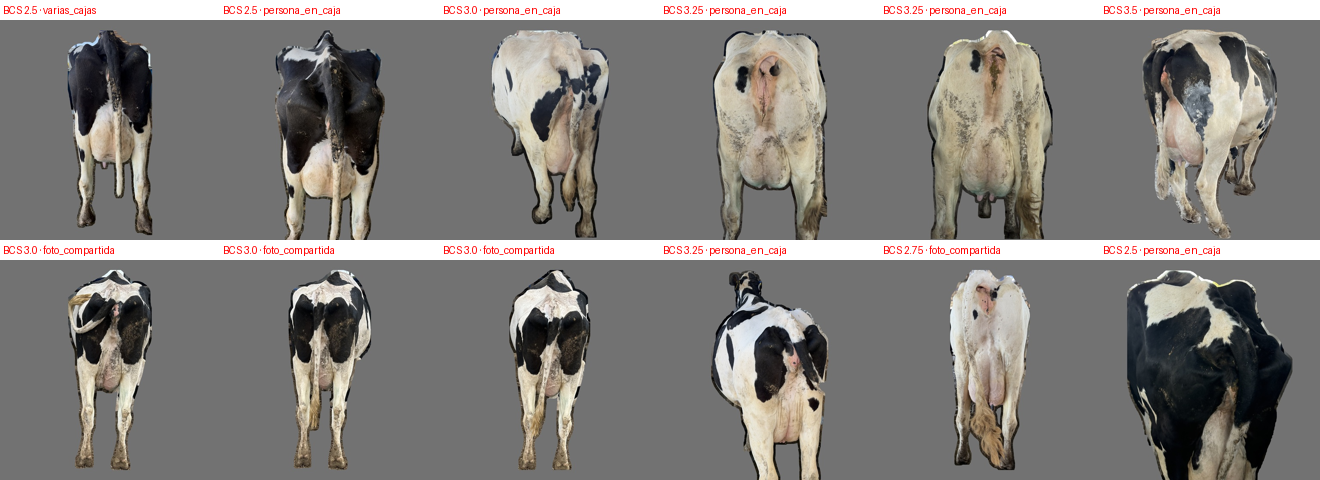

In [ ]:
if MOSTRAR_RECORTES and len(ok):
    orden = ok.assign(_sin=ok['avisos'].eq('')).sort_values(['_sin', 'id_vaca', 'stem']).head(12)
    mini = 220
    hoja = Image.new('RGB', (6 * mini, math.ceil(len(orden) / 6) * (mini + 20)), 'white')
    d = ImageDraw.Draw(hoja)
    for k, (_, f) in enumerate(orden.iterrows()):
        x, y = (k % 6) * mini, (k // 6) * (mini + 20)
        with Image.open(DATOS / f['archivo_mascara']) as im:
            hoja.paste(im.resize((mini, mini)), (x, y + 20))
        d.text((x + 3, y + 4), f"BCS {f['bcs']} · {(f['avisos'] or 'ok')[:24]}", fill='red' if f['avisos'] else 'green')
    display(hoja)

## Guardar `recortes_nube.zip` en Drive

In [ ]:
columnas = ['archivo_limpio', 'archivo_recorte', 'archivo_mascara', 'archivo_mascara_clahe', 'id_vaca', 'animal', 'ronda',
            'nombre_pan', 'bcs', 'vista', 'fuente', 'compartida_con', 'estado_recorte', 'avisos', 'area_mascara', 'persona',
            'x1', 'y1', 'x2', 'y2', 'xc', 'yc', 'wn', 'hn', 'ancho', 'alto']
salida_csv = fotos[[c for c in columnas if c in fotos.columns]].rename(columns={'estado_recorte': 'estado'})
salida_csv.to_csv(SALIDA / 'recortes.csv', index=False)
existen = all((DATOS / r).exists() for c in ['archivo_mascara', 'archivo_mascara_clahe'] for r in ok[c])
assert existen, 'Falta algún recorte'

zip_local = Path('/content/recortes_nube.zip')
with zipfile.ZipFile(zip_local, 'w', compression=zipfile.ZIP_STORED) as z:
    z.write(SALIDA / 'recortes.csv', 'datos/recortes/recortes.csv')
    for c in ['archivo_mascara', 'archivo_mascara_clahe']:
        for r in ok[c]:
            z.write(DATOS / r, f'datos/{r}')
destino = Path(CARPETA_TRABAJO) / 'recortes_nube.zip'
shutil.copy2(zip_local, destino)
print(f'Guardado {destino} ({destino.stat().st_size / 1e6:.0f} MB): {len(ok)} fotos × 2 variantes + recortes.csv')
print(pd.crosstab(salida_csv['ronda'], salida_csv['estado'], margins=True, margins_name='total').to_string())
print('\nSiguiente: libreta 02 · modelo en la nube.')

Guardado /content/drive/MyDrive/bcs_nube/recortes_nube.zip (73 MB): 604 fotos × 2 variantes + recortes.csv
estado  no_exportada   ok  total
ronda                           
1                  0  259    259
2                  4  345    349
total              4  604    608

Siguiente: libreta 02 · modelo en la nube.
